Images selected per category: 25
Training images: (112, 224, 224, 3)
Validation images: (28, 224, 224, 3)
Testing images: (35, 224, 224, 3)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,879,815 (56.76 MB)

 Trainable params: 7,244,551 (27.64 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.2054 - loss: 6.0034 - val_accuracy: 0.0714 - val_loss: 3.4835
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.2857 - loss: 3.0248 - val_accuracy: 0.2500 - val_loss: 2.3643
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.4821 - loss: 1.9084 - val_accuracy: 0.3571 - val_loss: 1.9655
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.5089 - loss: 1.5894 - val_accuracy: 0.4286 - val_loss: 1.7292
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.6518 - loss: 1.2418 - val_accuracy: 0.5357 - val_loss: 1.5020
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.6696 - loss: 0.9619 - val_accuracy: 0.5357 - val_loss: 1.3662
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.7500 - loss: 0.7717 - val_accuracy: 0.5357 - val_loss: 1.2227
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.6518 - loss: 1.0084 - val_accuracy: 0.6071 - val_loss:

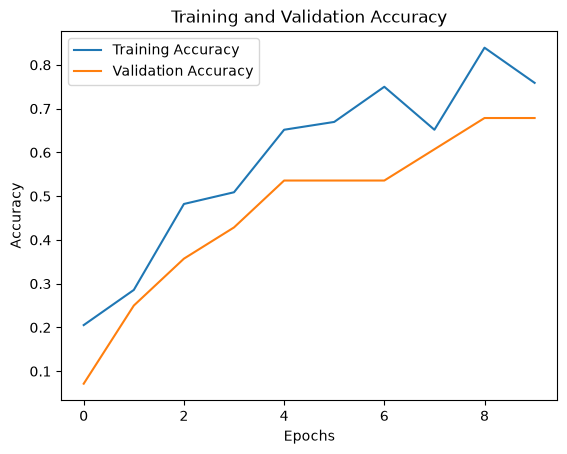

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 477ms/step - accuracy: 0.7714 - loss: 0.7472
Test Accuracy: 77.14 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 984ms/step


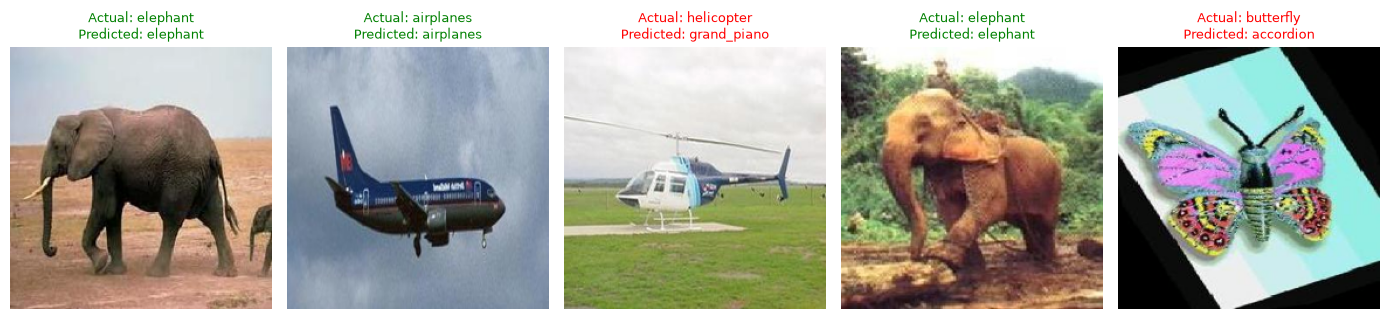

In [4]:

import zipfile
import tarfile
import pathlib
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# 1. Extract Caltech-101 dataset
ZIP_NAME = 'caltech-101.zip'
EXTRACT_TO = pathlib.Path('caltech101_extracted')
EXTRACT_TO.mkdir(exist_ok=True)

if not any(EXTRACT_TO.iterdir()):
    with zipfile.ZipFile(ZIP_NAME, 'r') as z:
        z.extractall(EXTRACT_TO)

# Find and extract the image archive
tar_files = list(EXTRACT_TO.rglob('101_ObjectCategories.tar.gz'))
assert tar_files, "Image archive not found!"

inner_root = tar_files[0].parent
images_dir = inner_root / '101_ObjectCategories'

if not images_dir.exists():
    with tarfile.open(tar_files[0], 'r:gz') as t:
        t.extractall(inner_root, filter='data')

# 2. Select five object categories
categories = [
    'accordion',
    'airplanes',
    'bonsai',
    'grand_piano',
    'butterfly',
    'elephant',
    'helicopter'
]

num_classes = len(categories)
img_size = (224, 224)

rng = np.random.default_rng(42)
image_data = []
labels = []
counts = []

# Count available images in each category
for category in categories:
    files = list((images_dir / category).glob('*'))
    files = [f for f in files if f.suffix.lower() in
             ['.jpg', '.jpeg', '.png']]
    counts.append(len(files))

assert min(counts) > 0, "One or more categories have no images!"

samples_per_class = min(25, min(counts))
print("Images selected per category:", samples_per_class)

# Load and resize images
for i, category in enumerate(categories):
    files = list((images_dir / category).glob('*'))
    files = [f for f in files if f.suffix.lower() in
             ['.jpg', '.jpeg', '.png']]

    selected_files = rng.choice(files, samples_per_class, replace=False)

    for file in selected_files:
        img = Image.open(file).convert('RGB')
        img = img.resize(img_size)
        image_data.append(np.array(img))
        labels.append(i)

X = np.array(image_data, dtype=np.float32)
y = np.array(labels)

# 3. Split into training, validation and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2,
    random_state=42, stratify=y_train
)

# Apply VGG16 preprocessing
X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)
X_test = preprocess_input(X_test)

# Convert labels into one-hot encoded form
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

# 4. Load pretrained VGG16 without its original classifier
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the lower convolutional layers
base_model.trainable = True

for layer in base_model.layers:
    if not layer.name.startswith('block5'):
        layer.trainable = False

# 5. Add custom classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# 6. Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 7. Train the model
history = model.fit(
    X_train,
    y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=10,
    batch_size=8
)

# 8. Display training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# 9. Evaluate using test images
loss, accuracy = model.evaluate(X_test, y_test_cat)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# 10. Predict categories for five sample test images
predictions = model.predict(X_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

# Reverse preprocessing to display the original images
display_images = X_test[:5] + [103.939, 116.779, 123.68]
display_images = display_images[..., ::-1]
display_images = np.clip(display_images, 0, 255).astype('uint8')

plt.figure(figsize=(14, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(display_images[i])

    actual = categories[y_test[i]]
    predicted = categories[predicted_labels[i]]

    plt.title(
        "Actual: " + actual + "\nPredicted: " + predicted,
        color='green' if y_test[i] == predicted_labels[i] else 'red',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()
